In [1]:
from    typing              import  Literal
from    math                import  log2, ceil
import  torch
from    matplotlib          import  pyplot  as  plt

In [12]:
DIMENSION = 2
RESOLUTIONS = {2: [64, 128], 3: [32, 64]}

In [13]:
files = [
    torch.load(f"relative_error__{DIMENSION}D_res{res:03d}.pth", weights_only=False)
    for res in RESOLUTIONS[DIMENSION]
]
for f in files:
    print(f.keys())

dict_keys(['error', 'exp_speed', 'min_t', 'max_t', 'res_t', 'res_v'])
dict_keys(['error', 'exp_speed', 'min_t', 'max_t', 'res_t', 'res_v'])


In [14]:
error1: torch.Tensor = files[0]['error']
error2: torch.Tensor = files[1]['error']

error1_mean = error1.mean(dim=0)
error2_mean = error2.mean(dim=0)
error1_std = error1.std(dim=0)
error2_std = error2.std(dim=0)

param1: torch.Tensor = files[0]['exp_speed']
param2: torch.Tensor = files[1]['exp_speed']

In [15]:
LabelTypes = Literal["suptitle", "title", "xlabel", "ylabel", "xticks", "yticks", "legend"]
fontsizes: dict[LabelTypes, int] = {
    "suptitle":     24*1.5,
    "title":        22*1.5,
    "xlabel":       18*1.5,
    "ylabel":       18*1.5,
    "xticks":       16*1.5,
    "yticks":       16*1.5,
    "legend":       16*1.5,
}
labels = [
    f"$N=2^{int(log2(files[0]['res_v']))}$, {len(param1)} trajectories, max: {error1_mean.max():.2e}",
    f"$N=2^{int(log2(files[1]['res_v']))}$, {len(param2)} trajectories, max: {error2_mean.max():.2e}"
]

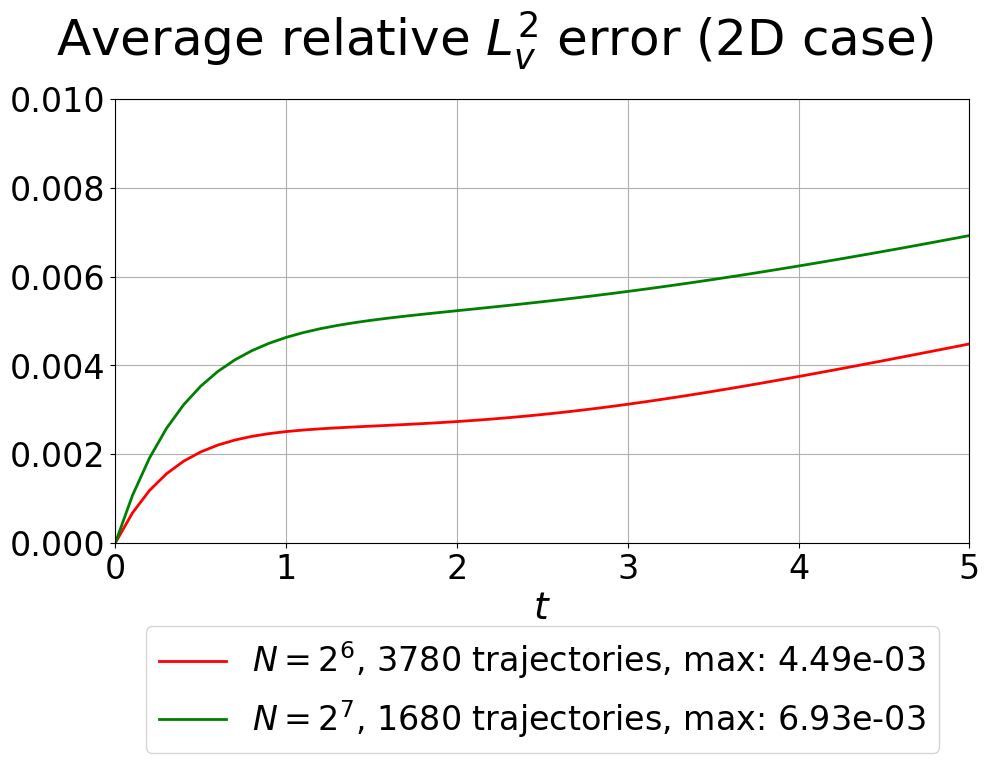

In [16]:
plt.figure(figsize=(10, 8))
plt.suptitle(f"Average relative $L^2_v$ error ({DIMENSION}D case)", fontsize=fontsizes['suptitle'])
arr_t = torch.linspace(files[0]['min_t'], files[0]['max_t'], files[0]['res_t'])
plt.plot(
    arr_t, error1_mean,
    'r-', linewidth=2,
    label=labels[0],
)
plt.plot(
    arr_t, error2_mean,
    'g-', linewidth=2,
    label=labels[1],
)
# plt.yscale('log')
plt.xlim(files[0]['min_t'], files[0]['max_t'])
plt.ylim(0, 1e-2 if DIMENSION==2 else 2e-2)
plt.xlabel('$t$', fontsize=fontsizes['xlabel'])
# plt.ylabel('Relative $L^2$ error', fontsize=fontsizes['ylabel'])
plt.tick_params(axis='both', which='major', labelsize=fontsizes['xticks'])
plt.legend(bbox_to_anchor=(0.5, -0.15), loc='upper center', fontsize=fontsizes['legend'], ncol=1)
plt.grid()
plt.tight_layout()

plt.savefig(f"relative_error__{DIMENSION}D__aggregated.pdf", bbox_inches='tight', dpi=600)
plt.show()

In [17]:
unique_params = torch.linspace(0, 1, 21)
unique_params_train = unique_params[::5]
unique_params_ood   = unique_params[~torch.isin(unique_params, unique_params_train)]
def partition_rel_error(rel_error: torch.Tensor, params: torch.Tensor) -> list[torch.Tensor]:
    return [
        rel_error[params.squeeze()==alpha]
        for alpha in params.unique()
    ]

partitioned_rel_error__01 = partition_rel_error(error1, param1)
partitioned_rel_error__02 = partition_rel_error(error2, param2)

partitioned_rel_error__01_mean = []
partitioned_rel_error__01_std  = []
for alpha, part_fno in zip(unique_params, partitioned_rel_error__01):
    partitioned_rel_error__01_mean.append(  part_fno.mean().item()  )
    partitioned_rel_error__01_std.append(   part_fno.std().item()   )
partitioned_rel_error__02_mean = []
partitioned_rel_error__02_std  = []
for alpha, part_fno in zip(unique_params, partitioned_rel_error__02):
    partitioned_rel_error__02_mean.append(  part_fno.mean().item()  )
    partitioned_rel_error__02_std.append(   part_fno.std().item()   )

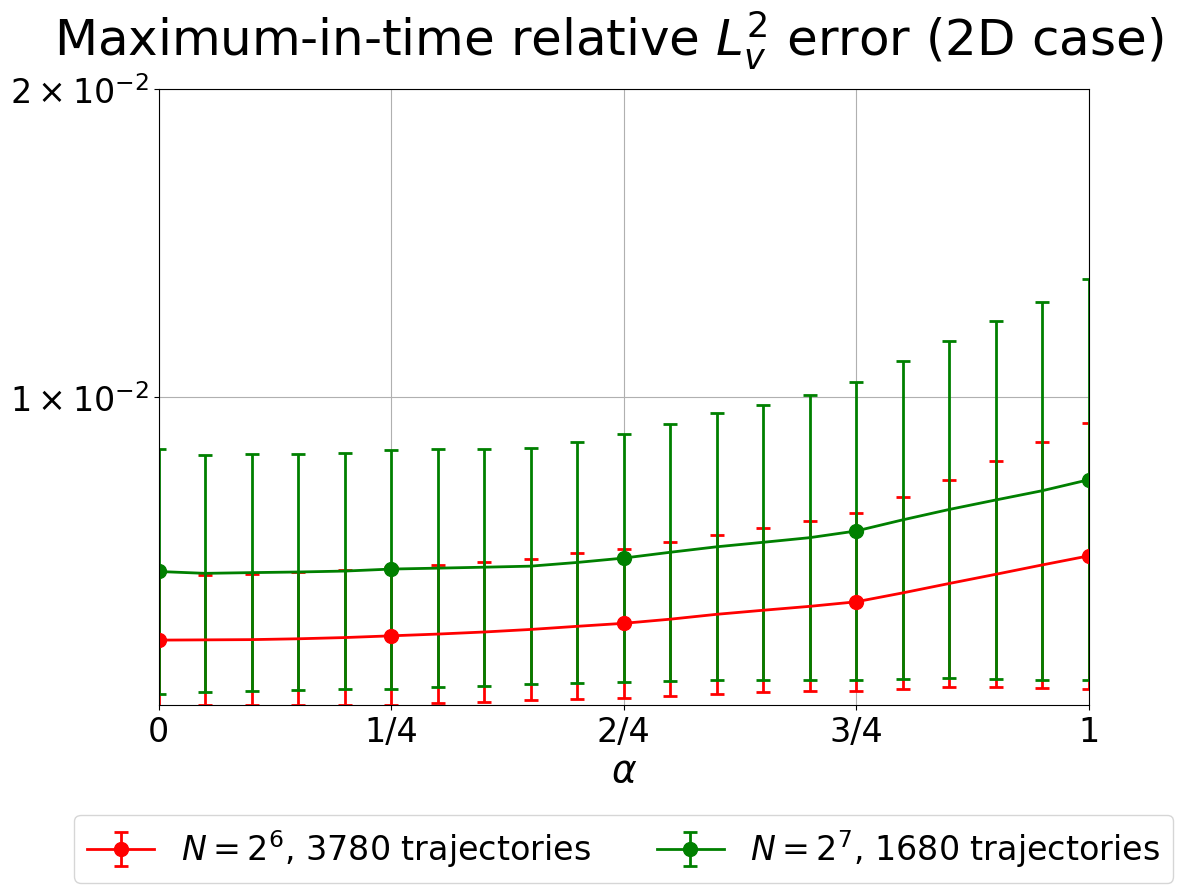

In [18]:
plt.figure(figsize=(12, 8))
plt.suptitle(rf"Maximum-in-time relative $L^2_v$ error ({DIMENSION}D case)", fontsize=fontsizes['suptitle'])
for list_mean, list_std, _color, _ls, _lbl in zip(
        [partitioned_rel_error__01_mean, partitioned_rel_error__02_mean],
        [partitioned_rel_error__01_std, partitioned_rel_error__02_std],
        ['r', 'g'],
        ['-', '-'],
        [
            f"$N=2^{int(log2(files[0]['res_v']))}$, {len(param1)} trajectories",
            f"$N=2^{int(log2(files[1]['res_v']))}$, {len(param2)} trajectories",
        ],
    ):
    plt.errorbar(
        unique_params, list_mean,
        yerr=list_std,
        color=_color, linestyle=_ls, linewidth=2,
        label=_lbl,
        marker='o', markevery=5, markersize=10,
        capsize=5, capthick=2,
    )

k_max = 2 if DIMENSION==2 else 5
plt.xlim(unique_params.min().item(), unique_params.max().item())
plt.ylim(0, k_max * 1e-2)
plt.xlabel(r"$\alpha$", fontsize=fontsizes['xlabel'])
# plt.ylabel("Relative $L^2$ error", fontsize=fontsizes['ylabel'])
# plt.yscale('log')
plt.xticks(unique_params_train, list(map(lambda x: f"{int(4*x)}/4" if 0<x and x<1 else f"{int(x)}", unique_params_train)))
plt.yticks([k*1e-2 for k in range(1, k_max+1)], [rf"${k} \times 10^{{-2}}$" for k in range(1, k_max+1)])
plt.tick_params(axis='both', which='both', labelsize=fontsizes['xticks'])
plt.legend(bbox_to_anchor=(0.5, -0.15), loc='upper center', fontsize=fontsizes['legend'], ncol=2)
plt.grid()
plt.savefig(f"relative_error__{DIMENSION}D__by_alpha.pdf", bbox_inches='tight')

End of file